In [9]:
# Importation des bibliothèques nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
# Configuration de l'affichage des graphiques
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

In [3]:
from google.colab import drive
# 1. Commande pour connecter / monter ton Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Chemin avec le dossier 'employés'
chemin_fichier = '/content/drive/MyDrive/employe/Extended_Employee_Performance_and_Productivity_Data.csv'

# Chargement du fichier
df = pd.read_csv(chemin_fichier)

In [6]:
# 3. Afficher les 5 premières lignes
df.head()

,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
0,1,IT,Male,55,Specialist,2022-01-19 08:03:05.556036,2,High School,5,6750.0,33,32,22,2,0,14,66,0,2.63,False
1,2,Finance,Male,29,Developer,2024-04-18 08:03:05.556036,0,High School,5,7500.0,34,34,13,14,100,12,61,2,1.72,False
2,3,Finance,Male,55,Specialist,2015-10-26 08:03:05.556036,8,High School,3,5850.0,37,27,6,3,50,10,1,0,3.17,False
3,4,Customer Support,Female,48,Analyst,2016-10-22 08:03:05.556036,7,Bachelor,2,4800.0,52,10,28,12,100,10,0,1,1.86,False
4,5,Engineering,Female,36,Analyst,2021-07-23 08:03:05.556036,3,Bachelor,2,4800.0,38,11,29,13,100,15,9,1,1.25,False


In [7]:
# Vérifier la structure du fichier (noms des colonnes, types, valeurs manquantes)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Employee_ID                  100000 non-null  int64  
 1   Department                   100000 non-null  object 
 2   Gender                       100000 non-null  object 
 3   Age                          100000 non-null  int64  
 4   Job_Title                    100000 non-null  object 
 5   Hire_Date                    100000 non-null  object 
 6   Years_At_Company             100000 non-null  int64  
 7   Education_Level              100000 non-null  object 
 8   Performance_Score            100000 non-null  int64  
 9   Monthly_Salary               100000 non-null  float64
 10  Work_Hours_Per_Week          100000 non-null  int64  
 11  Projects_Handled             100000 non-null  int64  
 12  Overtime_Hours               100000 non-null  int64  
 13  

In [8]:
# Tableau récapitulatif par département
stats_dept = df.groupby('Department').agg(
    Nombre_Employes=('Employee_ID', 'count'),
    Performance_Moyenne=('Performance_Score', 'mean'),
    Satisfaction_Moyenne=('Employee_Satisfaction_Score', 'mean'),
    Heures_Hebdo_Moyennes=('Work_Hours_Per_Week', 'mean'),
    Heures_Sup_Moyennes=('Overtime_Hours', 'mean')
).round(2)

print("--- STATISTIQUES PAR DÉPARTEMENT ---")
stats_dept

--- STATISTIQUES PAR DÉPARTEMENT ---


,Nombre_Employes,Performance_Moyenne,Satisfaction_Moyenne,Heures_Hebdo_Moyennes,Heures_Sup_Moyennes
Department,,,,,
Customer Support,11116,3.00,2.97,44.91,14.38
Engineering,10956,3.02,3.00,45.07,14.59
Finance,11200,2.98,3.00,44.89,14.34
HR,10960,3.00,3.00,44.93,14.58
IT,11131,3.00,3.02,44.93,14.67
Legal,11118,2.98,2.99,45.01,14.55
Marketing,11216,2.98,2.99,44.89,14.48
Operations,11181,3.01,3.03,44.97,14.52
Sales,11122,2.99,2.99,45.01,14.51


In [10]:

# 1. Test de Normalité sur la Performance
stat_norm, p_val_norm = stats.normaltest(df['Performance_Score'])

print(f"Test de Normalité (D'Agostino-Pearson) : p-value = {p_val_norm}")

if p_val_norm > 0.05:
    print("-> La distribution est NORMALE (On pourra utiliser l'ANOVA).")
else:
    print("-> La distribution n'est PAS NORMALE (On utilisera le test de Kruskal-Wallis).")

# 2. Test d'Homogénéité des Variances (Levene) entre Départements
groupes = [groupe['Performance_Score'].values for _, groupe in df.groupby('Department')]
stat_lev, p_val_lev = stats.levene(*groupes)

print(f"\nTest de Levene (Homogénéité des variances) : p-value = {p_val_lev}")
if p_val_lev > 0.05:
    print("-> Les variances sont HOMOGÈNES.")
else:
    print("-> Les variances sont HÉTÉROGÈNES.")

Test de Normalité (D'Agostino-Pearson) : p-value = 0.0
-> La distribution n'est PAS NORMALE (On utilisera le test de Kruskal-Wallis).

Test de Levene (Homogénéité des variances) : p-value = 0.39404796431122074
-> Les variances sont HOMOGÈNES.


In [11]:
# 1. Création de la table de contingence (Tableau croisé)
table_croisee = pd.crosstab(df['Department'], df['Education_Level'])

print("--- TABLE DE CONTINGENCE : Department vs Education_Level ---")
print(table_croisee)
print("\n" + "="*60 + "\n")

# 2. Test du Khi-deux (Chi-Square Test)
chi2_stat, p_val, dof, expected = stats.chi2_contingency(table_croisee)

print(f"Statistique Khi-deux (Chi2) : {chi2_stat:.4f}")
print(f"Degrés de liberté (dof)    : {dof}")
print(f"p-value                    : {p_val:.4e}")

# Interprétation de la p-value
if p_val < 0.05:
    print("-> CONCLUSION : La p-value < 0.05. Il existe une relation statistiquement SIGNIFICATIVE entre le Département et le Niveau d'études (On rejette H0).\n")
else:
    print("-> CONCLUSION : La p-value >= 0.05. Les variables sont INDÉPENDANTES (On ne rejette pas H0).\n")

# 3. Calcul du V de Cramer
n_obs = table_croisee.sum().sum()
min_dim = min(table_croisee.shape) - 1
cramer_v = np.sqrt(chi2_stat / (n_obs * min_dim))

print(f"V de Cramer : {cramer_v:.4f}")
if cramer_v < 0.1:
    print("-> Force de l'association : Très faible à négligeable")
elif cramer_v < 0.3:
    print("-> Force de l'association : Modérée")
else:
    print("-> Force de l'association : Forte")

# 4. Calcul du T de Tschuprow
r, c = table_croisee.shape
tschuprow_t = np.sqrt(chi2_stat / (n_obs * np.sqrt((r - 1) * (c - 1))))
print(f"T de Tschuprow : {tschuprow_t:.4f}")

--- TABLE DE CONTINGENCE : Department vs Education_Level ---
Education_Level   Bachelor  High School  Master  PhD
Department                                          
Customer Support      5501         3349    1692  574
Engineering           5534         3215    1640  567
Finance               5529         3427    1670  574
HR                    5561         3232    1612  555
IT                    5466         3450    1637  578
Legal                 5600         3356    1667  495
Marketing             5595         3375    1679  567
Operations            5606         3331    1686  558
Sales                 5649         3269    1621  583


Statistique Khi-deux (Chi2) : 28.4826
Degrés de liberté (dof)    : 24
p-value                    : 2.4021e-01
-> CONCLUSION : La p-value >= 0.05. Les variables sont INDÉPENDANTES (On ne rejette pas H0).

V de Cramer : 0.0097
-> Force de l'association : Très faible à négligeable
T de Tschuprow : 0.0076


In [12]:
# Extrait la liste des scores de performance pour chaque département
groupes_dept = [groupe['Performance_Score'].values for _, groupe in df.groupby('Department')]

# 1. ANOVA (Analyse de Variance)
stat_anova, p_val_anova = stats.f_oneway(*groupes_dept)

print("--- 1. TEST ANOVA (Comparaison globale des moyennes) ---")
print(f"Statistique F : {stat_anova:.4f}")
print(f"p-value       : {p_val_anova:.4e}")

if p_val_anova < 0.05:
    print("-> CONCLUSION : Il existe une différence significativement statistique de performance entre au moins deux départements (p < 0.05).\n")
else:
    print("-> CONCLUSION : Aucune différence significative de performance n'a été détectée entre les départements (p >= 0.05).\n")


# 2. Test de Kruskal-Wallis (Alternative non paramétrique)
stat_kw, p_val_kw = stats.kruskal(*groupes_dept)

print("--- 2. TEST DE KRUSKAL-WALLIS ---")
print(f"Statistique H : {stat_kw:.4f}")
print(f"p-value       : {p_val_kw:.4e}\n")


# 3. Test t de Student & Mann-Whitney U (Exemple : Engineering vs Customer Support)
perf_eng = df[df['Department'] == 'Engineering']['Performance_Score']
perf_cs = df[df['Department'] == 'Customer Support']['Performance_Score']

stat_t, p_val_t = stats.ttest_ind(perf_eng, perf_cs)
stat_mw, p_val_mw = stats.mannwhitneyu(perf_eng, perf_cs)

print("--- 3. COMPARAISON CIBLÉE (Engineering vs Customer Support) ---")
print(f"Test t de Student : t-stat = {stat_t:.4f}, p-value = {p_val_t:.4f}")
print(f"Mann-Whitney U    : U-stat = {stat_mw:.4f}, p-value = {p_val_mw:.4f}")

--- 1. TEST ANOVA (Comparaison globale des moyennes) ---
Statistique F : 0.9576
p-value       : 4.6732e-01
-> CONCLUSION : Aucune différence significative de performance n'a été détectée entre les départements (p >= 0.05).

--- 2. TEST DE KRUSKAL-WALLIS ---
Statistique H : 7.6579
p-value       : 4.6758e-01

--- 3. COMPARAISON CIBLÉE (Engineering vs Customer Support) ---
Test t de Student : t-stat = 1.2145, p-value = 0.2246
Mann-Whitney U    : U-stat = 61456705.0000, p-value = 0.2245


In [13]:
# Préparation des groupes de performance par département
groupes_dept = [groupe['Performance_Score'].values for _, groupe in df.groupby('Department')]

print("="*60)
print("--- POINT 3 : TESTS D'HOMOGÉNÉITÉ DES VARIANCES ---")
print("="*60)

# 1. Test de Levene
stat_lev, p_val_lev = stats.levene(*groupes_dept)
print(f"Test de Levene   : Stat = {stat_lev:.4f}, p-value = {p_val_lev:.4e}")

# 2. Test de Bartlett
stat_bart, p_val_bart = stats.bartlett(*groupes_dept)
print(f"Test de Bartlett : Stat = {stat_bart:.4f}, p-value = {p_val_bart:.4e}")

if p_val_lev > 0.05:
    print("-> CONCLUSION : Les variances sont HOMOGÈNES entre les départements.\n")
else:
    print("-> CONCLUSION : Les variances sont HÉTÉROGÈNES.\n")


print("="*60)
print("--- POINT 4 : TESTS DE NORMALITÉ (Performance_Score) ---")
print("="*60)

# Pour Shapiro-Wilk, on prend un échantillon de 5000 valeurs max
echantillon_perf = np.random.choice(df['Performance_Score'], size=5000, replace=False)

# 1. Test de Shapiro-Wilk
stat_shap, p_val_shap = stats.shapiro(echantillon_perf)
print(f"1. Shapiro-Wilk (n=5000) : Stat = {stat_shap:.4f}, p-value = {p_val_shap:.4e}")

# 2. Test de Kolmogorov-Smirnov (comparaison à une loi normale ajustée)
mu, std = df['Performance_Score'].mean(), df['Performance_Score'].std()
stat_ks, p_val_ks = stats.kstest(df['Performance_Score'], 'norm', args=(mu, std))
print(f"2. Kolmogorov-Smirnov   : Stat = {stat_ks:.4f}, p-value = {p_val_ks:.4e}")

# 3. Test de Jarque-Bera
stat_jb, p_val_jb = stats.jarque_bera(df['Performance_Score'])
print(f"3. Jarque-Bera          : Stat = {stat_jb:.4f}, p-value = {p_val_jb:.4e}")

--- POINT 3 : TESTS D'HOMOGÉNÉITÉ DES VARIANCES ---
Test de Levene   : Stat = 1.0518, p-value = 3.9405e-01
Test de Bartlett : Stat = 3.9548, p-value = 8.6118e-01
-> CONCLUSION : Les variances sont HOMOGÈNES entre les départements.

--- POINT 4 : TESTS DE NORMALITÉ (Performance_Score) ---
1. Shapiro-Wilk (n=5000) : Stat = 0.8878, p-value = 3.6804e-51
2. Kolmogorov-Smirnov   : Stat = 0.1605, p-value = 0.0000e+00
3. Jarque-Bera          : Stat = 7048.8455, p-value = 0.0000e+00


In [14]:
# Sélection des variables numériques clés
var_x = df['Work_Hours_Per_Week']
var_y = df['Performance_Score']
var_salary = df['Monthly_Salary']

print("="*65)
print("--- POINT 5 : CORRÉLATIONS (Heures Hebdo vs Score Performance) ---")
print("="*65)

# 1. Corrélation de Pearson
r_pearson, p_pearson = stats.pearsonr(var_x, var_y)
print(f"1. Pearson (r)  : Coeff = {r_pearson:.4f}, p-value = {p_pearson:.4e}")

# 2. Corrélation de Spearman
r_spearman, p_spearman = stats.spearmanr(var_x, var_y)
print(f"2. Spearman (ρ) : Coeff = {r_spearman:.4f}, p-value = {p_spearman:.4e}")

# 3. Tau de Kendall (échantillon de 5000 pour optimisation du temps de calcul)
var_x_sub = var_x.iloc[:5000]
var_y_sub = var_y.iloc[:5000]
tau_kendall, p_kendall = stats.kendalltau(var_x_sub, var_y_sub)
print(f"3. Kendall (τ)  : Coeff = {tau_kendall:.4f}, p-value = {p_kendall:.4e}")

print("\n" + "="*65)
print("--- CORRÉLATIONS (Salaire Mensuel vs Score Performance) ---")
print("="*65)

r_sal, p_sal = stats.pearsonr(var_salary, var_y)
rho_sal, p_rho_sal = stats.spearmanr(var_salary, var_y)
print(f"Pearson (Salaire vs Performance)  : Coeff = {r_sal:.4f}, p-value = {p_sal:.4e}")
print(f"Spearman (Salaire vs Performance) : Coeff = {rho_sal:.4f}, p-value = {p_rho_sal:.4e}")

--- POINT 5 : CORRÉLATIONS (Heures Hebdo vs Score Performance) ---
1. Pearson (r)  : Coeff = -0.0056, p-value = 7.5160e-02
2. Spearman (ρ) : Coeff = -0.0056, p-value = 7.5230e-02
3. Kendall (τ)  : Coeff = -0.0101, p-value = 3.3462e-01

--- CORRÉLATIONS (Salaire Mensuel vs Score Performance) ---
Pearson (Salaire vs Performance)  : Coeff = 0.5100, p-value = 0.0000e+00
Spearman (Salaire vs Performance) : Coeff = 0.4778, p-value = 0.0000e+00


Text(0.5, 1.0, '1. Matrice de Corrélation (Pearson)')

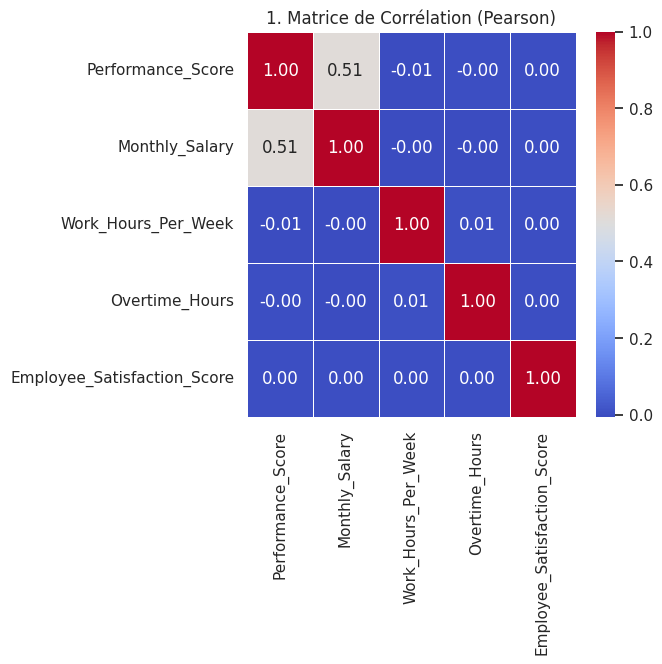

In [15]:
# Configuration générale
plt.figure(figsize=(18, 5))

# 1. HEATMAP DE CORRÉLATION
plt.subplot(1, 3, 1)
cols_quanti = ['Performance_Score', 'Monthly_Salary', 'Work_Hours_Per_Week', 'Overtime_Hours', 'Employee_Satisfaction_Score']
corr_matrix = df[cols_quanti].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("1. Matrice de Corrélation (Pearson)")

Text(0, 0.5, 'Salaire Mensuel ($)')

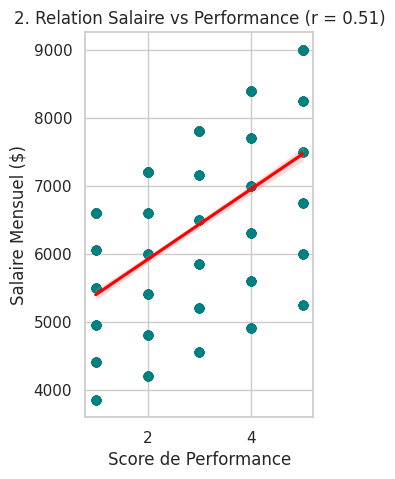

In [16]:
# 2. SCATTER PLOT : Salaire vs Performance
plt.subplot(1, 3, 2)
sns.regplot(data=df.sample(2000, random_state=42), x='Performance_Score', y='Monthly_Salary',
            scatter_kws={'alpha':0.3, 'color':'teal'}, line_kws={'color':'red'})
plt.title("2. Relation Salaire vs Performance (r = 0.51)")
plt.xlabel("Score de Performance")
plt.ylabel("Salaire Mensuel ($)")

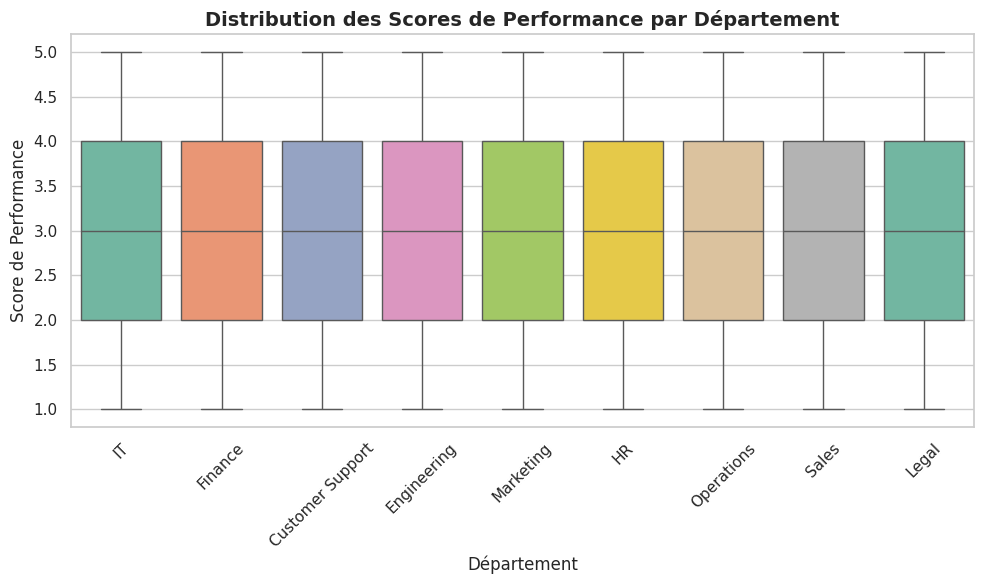

In [18]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Department', y='Performance_Score', hue='Department', palette='Set2', legend=False)
plt.xticks(rotation=45)
plt.title("Distribution des Scores de Performance par Département", fontsize=14, fontweight='bold')
plt.xlabel("Département", fontsize=12)
plt.ylabel("Score de Performance", fontsize=12)

plt.tight_layout()
plt.show()